# **NLP research Notebook**
This is the experimental notebook for NLP project that allow us to make some experiments and present the final project.
In the experiment section each experiments will have a key question we asked ourselves and the main goal will be to solve that. 

In [9]:
import os
import sys
import json
import time
import re
import math
from datetime import datetime
from pathlib import Path
from collections import defaultdict

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from transformers import pipeline
from huggingface_hub import utils

#some utils we will need later
sns.set_theme(style="whitegrid", palette="husl", font_scale=1.1)
plt.rcParams.update({"figure.dpi": 100, "savefig.bbox": "tight"})
LETTERS = ['A', 'B', 'C', 'D']

# **First step**
In this paragrapg we manage the connection with the game using api, we start the client and we define the utility functions that we will use to play the game or collect alla the info (play_game_with_model, json creation and save...). <br><br>
So we will create the logging function to collect all the info from each model run and save it in JSON format (in /runs folder) <br>
We will also define all the plotting function we will use at the end of each experiment in order to extract relevant results. 



## Manage connection to the environment
In this sub section we wil connect with the game 

In [10]:
#(LOCAL vs COLAB)
IN_COLAB = False
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    pass

if IN_COLAB:
    print("🌍 Detetected enviroment: COLAB")
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = Path('/content/drive/MyDrive/NLP/NLP_project')
else:
    print("💻 Detetected enviroment: LOCAL")
    BASE_DIR = Path('.')

OUTPUT_DIR = BASE_DIR 
RUNS_DIR = OUTPUT_DIR / 'runs'
PLOTS_DIR = OUTPUT_DIR / 'plots'
RUNS_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"runs directory: {RUNS_DIR}")
print(f"plot directory: {PLOTS_DIR}")

💻 Detetected enviroment: LOCAL
runs directory: runs
plot directory: plots


In [11]:
#manage the connection at polimilionaire 

package_parent_dir = './'
package_parent_dir = os.path.abspath(package_parent_dir)
#append to sys.path if it is not already present
if package_parent_dir not in sys.path:
    sys.path.append(package_parent_dir)

#import your package
from millionaire_client import MillionaireClient, AuthenticationError
import dotenv
dotenv.load_dotenv()

#credentiali per accedere al server
username = os.getenv('USER')
pwd = os.getenv('PASSWORD')
mail=os.getenv('MAIL')
API_URL = "http://131.175.15.22:51111/"

#create an instance of Client
client = MillionaireClient(API_URL)
#print(f"username: {username}, password: {pwd}, mail: {mail}, API_URL: {API_URL}")
try:
    # Authenticate with the server
    user = client.login(username, pwd)
    print("login successful :)")
    print(f"\n welcome, {user.username}, role: {user.role}")
except AuthenticationError as e:
    print(f"Login failed: {e}")
    
    
print("\n available competitions")
competitions = client.competitions.list_all()
for comp in competitions:
    print(f"  {comp.id}: {comp.name} ({comp.max_levels} questions)")
    print(f"_____________________Numer of questions: {comp.question_count}")
    print(f"_____________________Description of the competition:{comp.description}")

login successful :)

 welcome, Dav, role: student

 available competitions
  0: Entertainment (15 questions)
_____________________Numer of questions: 840
_____________________Description of the competition:Music, Movies, Celebrities and more
  1: Ancient History and Politics (15 questions)
_____________________Numer of questions: 454
_____________________Description of the competition:The Roman Empire, The Greeks, and more
  2: Science and Nature (15 questions)
_____________________Numer of questions: 5347
_____________________Description of the competition:Chemistry, Biology, Physics and similar subjects
  3: Maths (15 questions)
_____________________Numer of questions: 390
_____________________Description of the competition:Mathematics and Statistics from High School and College
  4: Philosophy and Psychology (15 questions)
_____________________Numer of questions: 3248
_____________________Description of the competition:Great thinkers and the human psyche
  5: News (15 questions)
___

## Model loading
Here we will define the function to load the LLM model that will be used to make all experiments. we define a catalogue of all the models we are going to try and their path, so we can load the model by simply call its name

In [12]:
MODEL_CATALOGUE = {
    #small model
    "Qwen2.5-3B":      "Qwen/Qwen2.5-3B-Instruct",
    "Phi3-mini":       "microsoft/Phi-3-mini-4k-instruct",
    #medium models
    "Llama3-8B":       "meta-llama/Meta-Llama-3-8B-Instruct",
    "Gemma2-9B":       "google/gemma-2-9b-it",
    "Mistral-7B":      "mistralai/Mistral-7B-Instruct-v0.3",
    "Qwen2.5-7B":      "Qwen/Qwen2.5-7B-Instruct",
    #thinking models 
    "DeepSeek-R1-7B":  "deepseek-ai/DeepSeek-R1-Distill-Qwen-7B",
    "QwQ-7B":          "Qwen/QwQ-7B",
}


In [13]:
#it takes the model name from the catalogue and a parameter if we want 
#to use quantization
def load_model(model_name: str, device_map: str = "auto",quantization_4_bit: bool = False):
  
    hf_name = MODEL_CATALOGUE.get(model_name)
    short_name = hf_name.split('/')[-1]
    hf_token = os.getenv("HF_TOKEN")
    kwargs = dict(model=hf_name, device_map=device_map,torch_dtype=torch.float16, token=hf_token,trust_remote_code=False)

    if quantization_4_bit:
        from transformers import BitsAndBytesConfig
        kwargs['quantization_config'] = BitsAndBytesConfig(load_in_4bit=True)
        kwargs.pop('torch_dtype', None)
        print("4 bit quantizzation")

    print(f"downloading the {short_name}")
    llm = pipeline("text-generation", **kwargs)
    dev = next(llm.model.parameters()).device
    print(f"Loaded:{short_name} on device: {dev}")
    return llm


## Prompt building
Here we build all the different prompt we will give to the model in order to study its behaviour. 
We build both text prompt and different way we give it to the model (one-shot, few shot, chain of thoughts). We will build both system prompt (the rules) and user prompt (the specific task)

In [14]:
SYSTEM_PROMPTS = {
    "zero_shot":
        "You are a trivia expert. Answer with ONLY a single letter: A, B, C, or D.",
    "few_shot":
        "You are a trivia expert. Answer with ONLY a single letter: A, B, C, or D.",
    "chain_of_thought":
        "You are a trivia expert. Think step by step, then on the LAST LINE write "
        "only the answer letter: A, B, C, or D.",
    "role_playing":
        "You are a world-class professor and trivia champion. "
        "Answer with ONLY a single letter: A, B, C, or D.",
    "formal":
        "You are a highly educated academic assistant. "
        "Respond with only the letter of the correct answer: A, B, C, or D.",
    "casual":
        "Hey, you're a trivia genius! Just pick the right letter — A, B, C, or D.",
    "math":
        "You are a mathematics professor. Solve step by step, then on the LAST LINE "
        "write only the answer letter: A, B, C, or D.",
    "rag":
        "You are a trivia expert with access to reference material. "
        "Use the provided context and answer with ONLY a single letter: A, B, C, or D.",
}

FEW_SHOT_EXAMPLES = [
    {"q": "What is the chemical symbol for Gold?",
     "opts": ["A: Ag", "B: Au", "C: Fe", "D: Pb"], "a": "B"},
    {"q": "In which year did World War II end?",
     "opts": ["A: 1943", "B: 1944", "C: 1945", "D: 1946"], "a": "C"},
]

In [15]:
#in this fuction we will build the prompt based on what we want to prove
def build_prompt(question: dict, opts: list, prompt_type: str = "zero_shot",rag_context: str = None, tool_result: str = None) -> str:
    question_text   = question.get('text')
    #build a row for each answer with the correct letter (A,B,C;D)
    opts_str = "\\n".join(f"{LETTERS[i]}: {o['text']}" for i, o in enumerate(opts[:4]))

    context_block = f"[Reference material]\\n{rag_context}\\n\\n" if rag_context else ""
    tool_block    = f"[Calculator result]\\n{tool_result}\\n\\n" if tool_result else ""

    #include the few shot examples
    few_shot_block = ""
    if prompt_type == "few_shot":
        examples = []
        for ex in FEW_SHOT_EXAMPLES:
            ex_opts = "\\n".join(ex["opts"])
            examples.append(f"Question: {ex['q']}\\nOptions:\\n{ex_opts}\\nAnswer: {ex['a']}")
        few_shot_block = "\\n\\n".join(examples) + "\\n\\nNow answer the following:\\n"

    #include the prompt that instruct the moodel to think step by step before answering
    cot_hint = "\\nThink step by step before answering." if prompt_type in ("chain_of_thought", "math") else ""

    #here we build the user prompt
    return (
        f"{context_block}{tool_block}{few_shot_block}"
        f"Question: {question_text}\\nOptions:\\n{opts_str}"
        f"{cot_hint}\\n"
        f"Answer with just the letter of the correct option (A, B, C, or D)."
    )

## Logging Module
Here we will define all the fuctions used to log in JSON each run of our model (a run is defined as a complete try of the model of each category). 
The created JSON will be saved in a /runs folder. We will define a META file with the usefult information in order to reconstruct the info of that run. init initialise always and define the meta value, log question saves all the question information about the run and then save run computes all the stats needed

In [16]:
#before starting the run we will create a META file with all the usefult information like model used, quantization, rag...
def init_run_log(metadata: dict) -> dict:
    ts = datetime.now().strftime("%Y%m%d_%H%M%S")
    #we define the id of the run 
    run_id = (f"run_{ts}"f"_{metadata.get('experiment_type','unknown')}"f"_{metadata.get('model_name','unknown').split('/')[-1]}")
    meta = {**metadata, "run_id": run_id, "timestamp": datetime.now().isoformat()}

    #initialise all at zero
    return {
        "run_metadata": meta,
        "session_stats": {
            "total_questions": 0,
            "correct": 0,
            "accuracy_on_played":  0.0,  # correct/played   
            "accuracy_on_possible": 0.0,  #correct /total questions per competition (15)
            "mean_confidence": 0.0,
            "mean_response_time_sec":0.0,
            "max_level_reached": 0,    
        },
        "category_stats":{},
        "questions":[],
    }

def log_question(run_data: dict, question_id: int, question: dict,model_answer: str,correct_answer: str,is_correct: bool,answer_probs: dict,confidence: float,response_time_sec: float,rag_context=None, tool_result=None):
    #for each question we append it to dict with all the information needed. 
    #Some info are included in the question obkect from the server while others are calculated by the generate_answer fucntion we use to play the game 
    run_data["questions"].append({
        "question_id": question_id,
        "level": question.get("level", question_id),
        "category": question.get("category", "unknown"),
        "question_text": question.get("text", ""),
        "options": question.get("options", {}),
        "correct_answer": correct_answer,     
        "model_answer": model_answer,       
        "is_correct": is_correct,    #from server
        "answer_probs": answer_probs,      
        "confidence": confidence,
        "response_time_sec": response_time_sec,
        "rag_context": bool(rag_context),
        "tool_result":tool_result,
    })


def save_run(run_data: dict, output_dir, max_q_per_game: int = 15) -> Path:
    #it computes the category stats of that run and then save it in a json file
    if isinstance(output_dir, str):
        output_dir = Path(output_dir)
    #takes all the questions  
    questions = run_data["questions"]
    n =len(questions)

    if n > 0:
        correct_n= sum(1 for q in questions if q["is_correct"])
        mean_time = sum(q["response_time_sec"] for q in questions)/n
        max_lvl= max(q["level"] for q in questions)    

        cat_map: dict = {}
        for q in questions:
            cat = q.get("category", "unknown")
            if cat not in cat_map:
                cat_map[cat] = {"total_answered": 0, "correct": 0,"accuracy_on_played": 0.0, "accuracy_on_possible": 0.0}
            cat_map[cat]["total_answered"] += 1
            if q["is_correct"]:
                cat_map[cat]["correct"] += 1
        for s in cat_map.values():
            ta = s["total_answered"]
            s["accuracy_on_played"]= s["correct"] / ta if ta else 0.0
            s["accuracy_on_possible"]= s["correct"]/ max_q_per_game

        n_cats = len(cat_map)
        confs  = [q["confidence"] for q in questions if q.get("confidence") is not None]

        run_data["session_stats"].update({
            "total_questions":        n,
            "correct":                correct_n,
            "accuracy_on_played":     correct_n / n if n else 0.0,
            "accuracy_on_possible":   correct_n / (n_cats * max_q_per_game) if n_cats else 0.0,
            "mean_confidence":        sum(confs)/len(confs) if confs else 0.0,
            "mean_response_time_sec": mean_time,
            "max_level_reached":      max_lvl,
        })
        run_data["category_stats"] = cat_map

    runs_dir  = output_dir / "runs"
    runs_dir.mkdir(parents=True, exist_ok=True)
    file_path = runs_dir / f"{run_data['run_metadata']['run_id']}.json"
    with open(file_path, 'w', encoding='utf-8') as f:
        json.dump(run_data, f, indent=2, ensure_ascii=False)
    print(f"saved to {file_path}")
    return file_path

## Tools and RAG 
Here we define the tools we will need for our model and the rag strategy we will use, we can change them here if we want to add a specific tool or make rag by a different source 

In [17]:
#tool that recognizes and expression in the text and if it finds it, then it calculates 
def try_calculator(question_text: str):
    pattern = '[\\d\\.]+(?:\\s*[\\+\\-\\*\\/\\^×÷]\\s*[\\d\\.]+)+'
    m = re.search(pattern, question_text)
    if m:
        try:
            expr = (m.group().replace('×','*').replace('÷','/').replace('^','**').strip())
            result = eval(expr, {"__builtins__": {}, "math": math})
            return f"{m.group().strip()} = {result}"
        except Exception:
            pass
    return None

#RAG from wikipedia, it returns a string with all the useful info has found
def fetch_wikipedia_context(question_text: str, max_chars: int = 600):
    try:
        import wikipedia
        wikipedia.set_lang("en")
        query = " ".join(question_text.split()[:8])
        results= wikipedia.search(query, results=3)
        if not results:
            return None
        for title in results:
            try:
                return wikipedia.summary(title, sentences=4)[:max_chars]
            except wikipedia.exceptions.DisambiguationError as e:
                try:
                    return wikipedia.summary(e.options[0], sentences=3)[:max_chars]
                except Exception:
                    continue
            except Exception:
                continue
        return None
    except Exception:
        return None

#here we define a different strategy for different questions (for example for math we enable thinking...)
def strategy_router(category: str, question_text: str, opts: list, llm_pipeline, base_prompt_type: str = "zero_shot",enable_rag: bool = False, enable_tools: bool = False):

    is_math = any(k in category.lower() for k in ("math", "statistic"))
    eff_prompt = base_prompt_type
    rag_ctx    = None
    tool_res   = None
    if is_math:
        eff_prompt = "math"
        if enable_tools:
            tool_res = try_calculator(question_text)

    if enable_rag and not is_math:
        rag_ctx = fetch_wikipedia_context(question_text)
        if rag_ctx:
            eff_prompt = "rag"

    return eff_prompt, rag_ctx, tool_res


## Play the game 
In this section i will define alla the function that will be used to play the game. We will define a function generate_answer that builds the prompt and gives it to the model in order to extract the answer and alla the useful stats, then a function play_game that iterates on all categories and play them all; this is where we log all questions and then save the json with all the stats 

In [18]:

_letter_id_cache: dict = {}
#the id of the letter depends on the tokenizer i use 
def _get_letter_token_ids(tokenizer) -> dict:
    ids = {}
    for letter in LETTERS:
        for variant in (f" {letter}", letter, f"▁{letter}"):
            enc = tokenizer.encode(variant, add_special_tokens=False)
            if enc:
                ids[letter] = enc[-1]
                break
    return ids

In [19]:
def generate_answer(question: dict, opts: list, llm_pipeline,prompt_type: str = "zero_shot", enable_thinking: bool = False, rag_context: str = None,tool_result: str = None):
    """
    it generate the answer and probability distribution over the 4 possibilities
    it returns the answer_id (option to submit to server), the chosen_letter,
    the inference_time in seconds, the confidence (probability to choose the answer)
    and the answer_probabilities {'A':p, 'B':p, 'C':p,'D': p}
    """
    tok = llm_pipeline.tokenizer
    sys_prompt = SYSTEM_PROMPTS.get(prompt_type, SYSTEM_PROMPTS["zero_shot"])
    usr_prompt= build_prompt(question, opts, prompt_type, rag_context, tool_result)

    messages= [{"role": "system", "content": sys_prompt},
                {"role": "user",   "content": usr_prompt}]
    #create the prompt text
    try:
        prompt_text = tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    except Exception:
        prompt_text= f"{sys_prompt}\\n{usr_prompt}\\nAnswer:"

    start = time.time()
    #tokenize the prompt to make it llm ready
    enc= tok(prompt_text, return_tensors="pt")
    enc= {k: v.to(llm_pipeline.model.device) for k, v in enc.items()}

    with torch.no_grad():
        out    = llm_pipeline.model(**enc)
        logits = out.logits[0, -1, :]         
    inference_time = time.time() - start

    #save in the cahe the id of that tokenizer so i don't 
    #calculate them every time, then builds a vector with the logits
    #and applies softmax to calculate probabilities 
    tok_id = id(tok)
    #if the id is not in the cache i save it 
    if tok_id not in _letter_id_cache:
        _letter_id_cache[tok_id] = _get_letter_token_ids(tok)
    lid = _letter_id_cache[tok_id]

    letter_logits = torch.tensor([logits[lid[l]].item() for l in LETTERS], dtype=torch.float32)
    probs_t= torch.softmax(letter_logits, dim=0)
    answer_probs= {l: probs_t[i].item() for i, l in enumerate(LETTERS)}
    best_idx      = torch.argmax(probs_t).item()
    chosen_letter = LETTERS[best_idx]
    confidence    = probs_t[best_idx].item()
    answer_id     = opts[best_idx]['id']

    print(f"  [{prompt_type}] "
          f"A={answer_probs['A']:.2f} B={answer_probs['B']:.2f} "
          f"C={answer_probs['C']:.2f} D={answer_probs['D']:.2f} "
          f"[{chosen_letter}] conf={confidence:.1%}  ({inference_time:.1f}s)")

    return answer_id, chosen_letter, inference_time, confidence, answer_probs

In [20]:
#function to play all competitions in sequence and log everything 
def play_game(client, model, run_metadata: dict, output_dir: Path,enable_rag: bool = False, enable_tools: bool = False) -> dict:
    """
    enable_rag fetch wikipedia context before each answering
    it then returns the completed run_log dict.
    """
    comps =client.competitions.list_all()
    run_log =init_run_log(run_metadata)
    prompt_type = run_metadata.get("prompt_type")
    enable_think= run_metadata.get("enable_thinking")

    for comp in comps:
        category = comp.name
        print(f"{'─'*55}")
        print(f"{category}(id={comp.id})")
        print(f"{'─'*55}")
        game    = client.game.start(competition_id=comp.id)
        q_count = 0
        while game.in_progress:
            question = game.current_question
            if question is None:
                break
            #list all the question options
            list_opts = [{"id": opt.id, "text": opt.text} for opt in question.options]
            q_dict    = {
                "text":        question.text,
                "level":       game.current_level,
                "category":    category,
                "competition": comp.name,
                "options":     {LETTERS[i]: opt.text for i, opt in enumerate(question.options[:4])},
            }

            #choose the strategy
            eff_prompt, rag_ctx, tool_res = strategy_router(category, question.text, list_opts, model,base_prompt_type=prompt_type,enable_rag=enable_rag, enable_tools=enable_tools)
            ##generate the answer
            answer_id, chosen_letter, exec_time, conf, probs = generate_answer( q_dict, list_opts, model,prompt_type=eff_prompt, enable_thinking=enable_think,rag_context=rag_ctx, tool_result=tool_res)
            #send to server the response
            result  = game.answer(answer_id)
            q_count += 1

            log_question(
                run_data=run_log, question_id=q_count, question=q_dict,
                model_answer=chosen_letter,  
                correct_answer="UNKNOWN",     
                is_correct=result.correct,     #from server 
                answer_probs=probs,
                confidence=conf, response_time_sec=exec_time,
                rag_context=rag_ctx, tool_result=tool_res)

            
            print(f"Q{q_count:2d} |[{chosen_letter}] " +
                  "+\n |"f"conf={conf:.1%} |{exec_time:.1f}s")
            if result.correct ==True:
                print("correct answer")
            else:
                print("wrong")

        print(f"ended at level {game.current_level}")

    save_run(run_log, output_dir)
    return run_log


## Data Loading
it load all the json in a dataframe we can use to plot all the useful data 

In [57]:
def load_runs(*args) -> pd.DataFrame:
    """
    Usage:
    load_runs(RUNS_DIR)  #all files in folder
    load_runs("runs/a.json", "runs/b.json") #specific files
    """
    paths = []
    for arg in args:
        p = Path(arg)
        if p.is_dir():
            paths.extend(sorted(p.glob("run_*.json")))
        elif p.is_file() and p.suffix == ".json":
            paths.append(p)

    all_rows = []
    for path in paths:
        with open(path, encoding='utf-8') as f:
            j = json.load(f)
        meta = j.get("run_metadata")
        for q in j.get("questions"):
            all_rows.append({**meta, **q})

    df = pd.DataFrame(all_rows)
    df = _compute_derived_fields(df)
    print(f"dataframe created")
    return df

#takes in input the dataframe created in load_runs and compute some stats 
def _compute_derived_fields(df: pd.DataFrame) -> pd.DataFrame:
   if df.empty:
       return df
 
   def _parse(x):
        if isinstance(x, dict): return x
        if isinstance(x, str):
            try: return json.loads(x.replace("'", '"'))
            except: return {}
        return {}

   if 'answer_probs' in df.columns:
        exp = df['answer_probs'].apply(_parse).apply(pd.Series)
        exp.columns = [f'prob_{c}' for c in exp.columns]
        df = pd.concat([df.reset_index(drop=True), exp.reset_index(drop=True)], axis=1)
        #uncertainty calculated as entropy
        def _entropy(row):
            ps = [max(row.get(f'prob_{l}', 0), 1e-10) for l in LETTERS]
            return -sum(p * math.log2(p) for p in ps)
        df['uncertainty'] = df.apply(_entropy, axis=1)

   if 'confidence' in df.columns and 'is_correct' in df.columns:
        df['prob_correct'] = df.apply(lambda r: r['confidence'] if r['is_correct'] else float('nan'), axis=1)

   if 'model_size' in df.columns:
        df['model_size_b'] = (df['model_size'].astype(str).str.extract('(\\d+\\.?\\d*)', expand=False).astype(float))
   if 'model_name' in df.columns:
        df['model_name'] = df['model_name'].str.split('/').str[-1]
   if 'is_correct' in df.columns:
        # Prevent conversion errors if there are NaNs/None 
        df['is_correct'] = df['is_correct'].fillna(False).astype(bool)

   return df

## Plotting Module 
define all the plotting functions to extract usefult graphs that we can use to extract usefult information about our experiments

In [60]:
PAL  = sns.color_palette("husl", 10)
STD  = (10, 6)
WIDE = (14, 6)
SQ   = (8, 8)

def _save(fig, name: str):
    path = PLOTS_DIR / f"{name}.png"
    fig.savefig(path, dpi=150, bbox_inches='tight')
    print(f"{path}")
    plt.show(); plt.close(fig)

def _ecdf(data):
    xs = np.sort(data)
    ys = np.arange(1, len(xs)+1) / len(xs)
    return xs, ys

#plot the accuracy based on different models, what model is better?, it is based only on the answered questions
def plot_accuracy_by_model(df: pd.DataFrame):
    # 1. Calcola l'accuracy per singola run
    run_accuracy = df.groupby(['model_name', 'run_id'])['is_correct'].mean().reset_index()
    # 2. Aggrega la media e std delle run
    gb = run_accuracy.groupby('model_name')['is_correct'].agg(['mean', 'std']).reset_index()
    gb = gb.rename(columns={'model_name':'Model', 'mean':'Accuracy', 'std':'Std'}).sort_values('Accuracy', ascending=False)
    gb['Std'] = gb['Std'].fillna(0)

    fig,ax =plt.subplots(figsize=STD)
    bars= ax.barh(gb['Model'], gb['Accuracy'], xerr=gb['Std'], capsize=5, color=PAL[:len(gb)],edgecolor='white')
    ax.set_xlim(0, 1)
    ax.set_xlabel('Accuracy (mean ± std)')
    ax.set_title('Accuracy by model (on Played Questions)', fontweight='bold')
    ax.axvline(0.25, ls='--', color='gray', alpha=0.6, label='Random (25%)')
    for bar, v in zip(bars, gb['Accuracy']):
        ax.text(bar.get_width()+.01, bar.get_y()+bar.get_height()/2,f'{v:.1%}', va='center', fontsize=9)
    ax.legend(); fig.tight_layout()
    _save(fig, "01_accuracy_by_model")

#plot the total accuracy based on maximum possible questions (15 per category)
def plot_accuracy_by_model_total(df: pd.DataFrame):
    # Calcola su totale domande (15 per category per run)
    def calc_total_acc(run_df):
        cats = run_df['category'].nunique()
        total_possible = cats * 15 # come da max_q_per_game
        return run_df['is_correct'].sum() / total_possible
        
    run_accuracy = df.groupby(['model_name', 'run_id']).apply(calc_total_acc).reset_index(name='is_correct')
    gb = run_accuracy.groupby('model_name')['is_correct'].agg(['mean', 'std']).reset_index()
    gb = gb.rename(columns={'model_name':'Model', 'mean':'Accuracy', 'std':'Std'}).sort_values('Accuracy', ascending=False)
    gb['Std'] = gb['Std'].fillna(0)

    fig,ax =plt.subplots(figsize=STD)
    bars= ax.barh(gb['Model'], gb['Accuracy'], xerr=gb['Std'], capsize=5, color=PAL[:len(gb)],edgecolor='white')
    ax.set_xlim(0, 1)
    ax.set_xlabel('Accuracy (mean ± std)')
    ax.set_title('Accuracy by model (on Total Possible Questions)', fontweight='bold')
    ax.axvline(0.25, ls='--', color='gray', alpha=0.6, label='Random (25%)')
    for bar, v in zip(bars, gb['Accuracy']):
        ax.text(bar.get_width()+.01, bar.get_y()+bar.get_height()/2,f'{v:.1%}', va='center', fontsize=9)
    ax.legend(); fig.tight_layout()
    _save(fig, "01b_accuracy_by_model_total")


# ── Plot 2: Accuracy by category ──────────────────────────────────────────
def plot_accuracy_by_category(df: pd.DataFrame):
    """Dove sbaglia di più? Category breakdown across models"""
    run_cat_acc = df.groupby(['model_name','category','run_id'])['is_correct'].mean().reset_index()
    gb = run_cat_acc.groupby(['model_name','category'])['is_correct'].agg(['mean', 'std']).reset_index()
    gb = gb.rename(columns={'model_name':'Model','category':'Category', 'mean':'Accuracy', 'std':'Std'})
    gb['Std'] = gb['Std'].fillna(0)

    fig, ax = plt.subplots(figsize=WIDE)
    pivot_mean = gb.pivot(index='Category', columns='Model', values='Accuracy')
    pivot_std = gb.pivot(index='Category', columns='Model', values='Std')
    
    pivot_mean.plot(kind='barh', ax=ax, xerr=pivot_std, capsize=3)
    ax.set_xlim(0, 1)
    ax.axvline(0.25, ls='--', color='gray', alpha=0.5, label='Random')
    ax.set_title('📊 Plot 2 — Accuracy by Category', fontweight='bold')
    ax.set_xlabel('Accuracy (mean ± std)'); ax.legend(bbox_to_anchor=(1.01,1), loc='upper left')
    fig.tight_layout(); _save(fig, "02_accuracy_by_category")


# ── Plot 3: Heatmap model × prompt ────────────────────────────────────────
def plot_heatmap_model_prompt(df: pd.DataFrame):
    """Il prompt cambia l'accuracy? Heatmap reveals the truth"""
    if 'prompt_type' not in df.columns or df['prompt_type'].nunique() < 2:
        print("⚠️  Need multiple prompt_types. Skipping plot 3.")
        return
    pivot = df.groupby(['model_name','prompt_type'])['is_correct'].mean().unstack()
    fig, ax = plt.subplots(figsize=SQ)
    sns.heatmap(pivot, annot=True, fmt='.1%', cmap='YlOrRd',
                vmin=0, vmax=1, ax=ax, linewidths=.5, cbar_kws={'label':'Accuracy'})
    ax.set_title('📊 Plot 3 — Accuracy: Model × Prompt Type', fontweight='bold')
    ax.set_xlabel('Prompt Type'); ax.set_ylabel('Model')
    fig.tight_layout(); _save(fig, "03_heatmap_model_prompt")


# ── Plot 4: Accuracy by difficulty ────────────────────────────────────────
def plot_accuracy_by_difficulty(df: pd.DataFrame):
    """Few-shot aiuta su domande difficili? Difficulty curves"""
    if 'level' not in df.columns:
        print("⚠️  No level column. Skipping plot 4."); return

    fig, axes = plt.subplots(1, 2, figsize=WIDE)

    ax = axes[0]
    col = 'prompt_type' if 'prompt_type' in df.columns else 'experiment_type'
    for label, sub in df.groupby(col):
        lvl = sub.groupby('level')['is_correct'].mean()
        ax.plot(lvl.index, lvl.values, marker='o', label=label)
    ax.axhline(0.25, ls='--', color='gray', alpha=0.5, label='Random')
    ax.set_ylim(-0.05, 1.05)
    ax.set_xlabel('Question Level'); ax.set_ylabel('Accuracy')
    ax.set_title('Accuracy vs Level by Strategy')
    ax.legend(fontsize=8)

    ax2 = axes[1]
    for cat, sub in df.groupby('category'):
        lvl = sub.groupby('level')['is_correct'].mean()
        ax2.plot(lvl.index, lvl.values, marker='s', label=cat, alpha=0.8)
    ax2.axhline(0.25, ls='--', color='gray', alpha=0.5)
    ax2.set_ylim(-0.05, 1.05)
    ax2.set_xlabel('Question Level'); ax2.set_ylabel('Accuracy')
    ax2.set_title('Accuracy vs Level by Category')
    ax2.legend(fontsize=8)

    fig.suptitle('📊 Plot 4 — Accuracy by Difficulty Level', fontweight='bold')
    fig.tight_layout(); _save(fig, "04_accuracy_by_difficulty")


# ── Plot 5: Calibration ───────────────────────────────────────────────────
def plot_calibration(df: pd.DataFrame):
    """È overconfident? Reliability diagram — the most honest plot"""
    if 'confidence' not in df.columns:
        print("⚠️  No confidence column. Skipping plot 5."); return

    bins = np.linspace(0, 1, 11)
    bin_mids, acc_means, conf_means, ns = [], [], [], []
    for i in range(10):
        mask = (df['confidence'] >= bins[i]) & (df['confidence'] < bins[i+1])
        sub  = df[mask]
        if len(sub) < 2: continue
        bin_mids.append((bins[i]+bins[i+1])/2)
        acc_means.append(sub['is_correct'].mean())
        conf_means.append(sub['confidence'].mean())
        ns.append(len(sub))

    # Expected Calibration Error
    ece = sum(ns[i]/len(df) * abs(conf_means[i]-acc_means[i]) for i in range(len(ns)))

    fig, axes = plt.subplots(1, 2, figsize=WIDE)

    ax = axes[0]
    ax.plot([0,1],[0,1],'k--', lw=1.5, label='Perfect calibration')
    sc = ax.scatter(conf_means, acc_means, c=ns, cmap='viridis', s=120, zorder=4)
    ax.plot(conf_means, acc_means, 'b-', alpha=0.5)
    plt.colorbar(sc, ax=ax, label='# questions in bin')
    ax.fill_between([0,1],[0,1],[1,1], alpha=0.05, color='red', label='Overconfident zone')
    ax.fill_between([0,1],[0,0],[0,1], alpha=0.05, color='green', label='Underconfident zone')
    ax.set_xlabel('Mean Confidence'); ax.set_ylabel('Actual Accuracy')
    ax.set_xlim(0,1); ax.set_ylim(0,1)
    ax.set_title(f'Reliability Diagram  (ECE={ece:.3f})')
    ax.legend(fontsize=8)

    ax2 = axes[1]
    for cat, sub in df.groupby('category'):
        cuts = pd.cut(sub['confidence'], bins=5, labels=False)
        cat_acc  = sub.groupby(cuts)['is_correct'].mean()
        cat_conf = sub.groupby(cuts)['confidence'].mean()
        ax2.plot(cat_conf.values, cat_acc.values, marker='o', label=cat, alpha=0.8)
    ax2.plot([0,1],[0,1],'k--', lw=1, alpha=0.5)
    ax2.set_xlabel('Mean Confidence'); ax2.set_ylabel('Accuracy')
    ax2.set_title('Calibration by Category')
    ax2.legend(fontsize=8)

    fig.suptitle('📊 Plot 5 — Calibration (Overconfidence?)', fontweight='bold')
    fig.tight_layout(); _save(fig, "05_calibration")


# ── Plot 6: Confidence distribution ──────────────────────────────────────
def plot_confidence_distribution(df: pd.DataFrame):
    """Distingue quando sa da quando non sa? Confidence histograms + ECDF"""
    fig, axes = plt.subplots(1, 2, figsize=WIDE)

    ax = axes[0]
    for is_c, lbl, clr in [(True,'Correct','#2ecc71'),(False,'Wrong','#e74c3c')]:
        sub = df[df['is_correct']==is_c]['confidence'].dropna()
        ax.hist(sub, bins=20, alpha=0.55, color=clr, label=f'{lbl} (n={len(sub)})',
                density=True, edgecolor='white')
    ax.set_xlabel('Confidence'); ax.set_ylabel('Density')
    ax.set_title('Confidence Distribution')
    ax.legend()

    ax2 = axes[1]
    for is_c, lbl, clr in [(True,'Correct','#2ecc71'),(False,'Wrong','#e74c3c')]:
        sub = df[df['is_correct']==is_c]['confidence'].dropna().values
        if len(sub) > 0:
            xs, ys = _ecdf(sub)
            ax2.plot(xs, ys, color=clr, lw=2, label=lbl)
    ax2.set_xlabel('Confidence'); ax2.set_ylabel('Cumulative Probability')
    ax2.set_title('Confidence ECDF'); ax2.legend()

    fig.suptitle("📊 Plot 6 — Confidence: Knows vs Doesn't Know", fontweight='bold')
    fig.tight_layout(); _save(fig, "06_confidence_distribution")


# ── Plot 7: prob_correct by category ─────────────────────────────────────
def plot_prob_correct_by_category(df: pd.DataFrame):
    """Quando sbaglia, era vicino o lontano? Confidence for correct answers"""
    correct_df = df[df['is_correct']].copy()
    if correct_df.empty:
        print("⚠️  No correct answers in dataset. Skipping plot 7."); return

    cats = sorted(df['category'].unique())
    data_c = [correct_df[correct_df['category']==c]['confidence'].dropna() for c in cats]
    data_w = [df[(df['category']==c) & (~df['is_correct'])]['confidence'].dropna() for c in cats]

    fig, ax = plt.subplots(figsize=STD)
    positions = np.arange(len(cats))
    bp = ax.boxplot(data_c, positions=positions, widths=0.5,
                    patch_artist=True, notch=False)
    for patch, clr in zip(bp['boxes'], PAL): patch.set_facecolor(clr); patch.set_alpha(0.7)

    # Wrong answer mean confidence as red ×
    for i, (cat, sub_w) in enumerate(zip(cats, data_w)):
        if len(sub_w) > 0:
            ax.scatter(i, sub_w.mean(), color='red', marker='x', s=120, zorder=5,
                       label='Wrong (mean conf)' if i==0 else "")

    ax.set_xticks(positions); ax.set_xticklabels(cats, rotation=20, ha='right')
    ax.set_ylabel('Confidence'); ax.set_ylim(0, 1.05)
    ax.set_title('📊 Plot 7 — Confidence (Correct ✓ box / Wrong ✗ mean) by Category',
                 fontweight='bold')
    ax.legend(); fig.tight_layout(); _save(fig, "07_prob_correct_by_category")


# ── Plot 8: RAG comparison ────────────────────────────────────────────────
def plot_rag_comparison(df: pd.DataFrame):
    """RAG aiuta? Per categoria, dove migliora e dove peggiora"""
    if 'rag_context' not in df.columns or df['rag_context'].nunique() < 2:
        print("⚠️  Need RAG and non-RAG runs. Skipping plot 8."); return

    run_rag_acc = df.groupby(['category','rag_context', 'run_id'])['is_correct'].mean().reset_index()
    gb = run_rag_acc.groupby(['category','rag_context'])['is_correct'].agg(['mean', 'std']).reset_index()
    gb = gb.rename(columns={'category':'Category', 'rag_context':'RAG', 'mean':'Accuracy', 'std':'Std'})
    gb['RAG'] = gb['RAG'].map({True:'With RAG', False:'Without RAG'})
    gb['Std'] = gb['Std'].fillna(0)

    fig, ax = plt.subplots(figsize=STD)
    pivot_mean = gb.pivot(index='Category', columns='RAG', values='Accuracy')
    pivot_std = gb.pivot(index='Category', columns='RAG', values='Std')
    
    pivot_mean.plot(kind='bar', ax=ax, yerr=pivot_std, capsize=3, color=['#e74c3c','#2ecc71'], edgecolor='white')
    ax.set_ylim(0,1); ax.set_xlabel('Category'); ax.set_ylabel('Accuracy (mean ± std)')
    ax.axhline(0.25, ls='--', color='gray', alpha=0.5, label='Random')
    ax.set_title('📊 Plot 8 — RAG vs No-RAG by Category', fontweight='bold')
    ax.legend(); plt.xticks(rotation=25, ha='right')
    fig.tight_layout(); _save(fig, "08_rag_comparison")


# ── Plot 9: Accuracy vs Latency ───────────────────────────────────────────
def plot_accuracy_vs_latency(df: pd.DataFrame):
    """Tradeoff accuracy/velocità. Pareto frontier, find we must"""
    # 2-step per la stdev!
    run_agg = df.groupby(['model_name', 'run_id']).agg(
        Accuracy=('is_correct','mean'),
        Latency=('response_time_sec','mean')
    ).reset_index()
    
    gb = run_agg.groupby('model_name').agg(
        Accuracy=('Accuracy','mean'),
        Acc_std=('Accuracy','std'),
        Latency=('Latency','mean'),
        Lat_std=('Latency','std'),
        Count=('Accuracy','count')
    ).reset_index().fillna(0)

    fig, ax = plt.subplots(figsize=STD)
    
    ax.errorbar(gb['Latency'], gb['Accuracy'], xerr=gb['Lat_std'], yerr=gb['Acc_std'], 
                fmt='none', ecolor='gray', alpha=0.5, capsize=3, zorder=1)
                
    sc = ax.scatter(gb['Latency'], gb['Accuracy'],
                    s=gb['Count']*80, c=range(len(gb)), cmap='tab10',
                    alpha=0.85, edgecolors='black', lw=0.5, zorder=2)
    for _, row in gb.iterrows():
        ax.annotate(row['model_name'], (row['Latency'], row['Accuracy']),
                    textcoords="offset points", xytext=(6,4), fontsize=9)
    ax.axhline(0.25, ls='--', color='gray', alpha=0.5, label='Random')
    ax.axvline(30, ls='--', color='red', alpha=0.5, label='30s timeout')
    ax.set_xlabel('Mean Response Time (s)'); ax.set_ylabel('Accuracy')
    ax.set_ylim(0,1)
    ax.set_title('📊 Plot 9 — Accuracy vs Latency Tradeoff', fontweight='bold')
    ax.annotate('↖ Ideal', xy=(2, 0.82), color='green', fontsize=11, alpha=0.7)
    ax.legend(); fig.tight_layout(); _save(fig, "09_accuracy_vs_latency")


# ── Plot 10: Accuracy by model size ──────────────────────────────────────
def plot_accuracy_by_model_size(df: pd.DataFrame):
    """Bigger is always better? Size vs accuracy — the eternal question"""
    if 'model_size_b' not in df.columns:
        print("⚠️  No model_size_b. Add 'model_size' to metadata. Skipping plot 10.")
        return

    run_size = df.groupby(['model_name','model_size_b','quantization','run_id'])['is_correct'].mean().reset_index()
    gb = run_size.groupby(['model_name','model_size_b','quantization'])['is_correct'].agg(['mean', 'std']).reset_index()
    gb = gb.rename(columns={'mean':'Accuracy', 'std':'Std'}).fillna(0)

    fig, ax = plt.subplots(figsize=STD)
    for i, (quant, sub) in enumerate(gb.groupby('quantization')):
        ax.errorbar(sub['model_size_b'], sub['Accuracy'], yerr=sub['Std'], fmt='none', ecolor=PAL[i], alpha=0.5, capsize=3)
        ax.scatter(sub['model_size_b'], sub['Accuracy'], s=180,
                   label=f"quant={quant}", zorder=3, color=PAL[i])
        for _, row in sub.iterrows():
            ax.annotate(row['model_name'], (row['model_size_b'], row['Accuracy']),
                        textcoords="offset points", xytext=(4,5), fontsize=8)
    ax.axhline(0.25, ls='--', color='gray', alpha=0.5, label='Random')
    ax.set_xlabel('Model Size (B params)'); ax.set_ylabel('Accuracy (mean ± std)')
    ax.set_ylim(0,1)
    ax.set_title('📊 Plot 10 — Accuracy by Model Size', fontweight='bold')
    ax.legend(title='Quantization'); fig.tight_layout()
    _save(fig, "10_accuracy_by_model_size")


# ── Plot 11: Letter choice patterns ──────────────────────────────────────
def plot_letter_confusion(df: pd.DataFrame):
    """Gli errori sono sistematici? Letter choice bias — no correct answer needed"""
    fig, axes = plt.subplots(1, 2, figsize=WIDE)

    ax = axes[0]
    lc = df['model_answer'].value_counts().reindex(LETTERS, fill_value=0)
    colors = ['#e74c3c' if l==lc.idxmax() else '#95a5a6' for l in LETTERS]
    ax.bar(LETTERS, lc.values, color=colors, edgecolor='white')
    ax.axhline(len(df)/4, ls='--', color='navy', alpha=0.7, label='Expected (uniform)')
    ax.set_title('Letter Choice Distribution (all answers)')
    ax.set_xlabel('Chosen Letter'); ax.set_ylabel('Count'); ax.legend()

    ax2 = axes[1]
    for cat, sub in df.groupby('category'):
        freqs = sub['model_answer'].value_counts().reindex(LETTERS, fill_value=0)
        ax2.plot(LETTERS, freqs.values / freqs.sum(), marker='o',
                 label=cat, alpha=0.8)
    ax2.axhline(0.25, ls='--', color='gray', alpha=0.5, label='Uniform 25%')
    ax2.set_title('Normalised Letter Frequency by Category')
    ax2.set_xlabel('Letter'); ax2.set_ylabel('Frequency'); ax2.legend(fontsize=8)

    fig.suptitle('📊 Plot 11 — Letter Choice Patterns (Systematic Bias?)',
                 fontweight='bold')
    fig.tight_layout(); _save(fig, "11_letter_confusion")


# ── Plot 12: Thinking vs Standard ────────────────────────────────────────
def plot_thinking_vs_standard(df: pd.DataFrame):
    """I thinking models stanno nel timeout? Accuracy and latency side-by-side"""
    if 'enable_thinking' not in df.columns or df['enable_thinking'].nunique() < 2:
        print("⚠️  Need thinking=True and False runs. Skipping plot 12."); return

    df2 = df.copy()
    df2['Mode'] = df2['enable_thinking'].map({True:'Thinking 🧠', False:'Standard ⚡'})
    
    run_agg = df2.groupby(['model_name','Mode','run_id']).agg(
        Accuracy=('is_correct','mean'),
        Latency=('response_time_sec','mean'),
        LatP95=('response_time_sec', lambda x: x.quantile(0.95))
    ).reset_index()
    
    gb = run_agg.groupby(['model_name','Mode']).agg(
        Accuracy=('Accuracy','mean'),
        Acc_std=('Accuracy','std'),
        Latency=('Latency','mean'),
        Lat_std=('Latency','std'),
    ).reset_index().fillna(0)

    fig, axes = plt.subplots(1, 2, figsize=WIDE)

    pivot_a = gb.pivot(index='model_name', columns='Mode', values='Accuracy')
    pivot_a_std = gb.pivot(index='model_name', columns='Mode', values='Acc_std')
    pivot_a.plot(kind='bar', ax=axes[0], yerr=pivot_a_std, capsize=3, color=['#e74c3c','#3498db'], edgecolor='white')
    axes[0].set_ylim(0,1); axes[0].set_title('Accuracy')
    axes[0].axhline(0.25, ls='--', color='gray', alpha=0.5)
    axes[0].set_xlabel(''); plt.setp(axes[0].get_xticklabels(), rotation=30, ha='right')

    pivot_l = gb.pivot(index='model_name', columns='Mode', values='Latency')
    pivot_l_std = gb.pivot(index='model_name', columns='Mode', values='Lat_std')
    pivot_l.plot(kind='bar', ax=axes[1], yerr=pivot_l_std, capsize=3, color=['#e74c3c','#3498db'], edgecolor='white')
    axes[1].axhline(30, ls='--', color='red', alpha=0.8, label='30s timeout')
    axes[1].set_title('Mean Response Time (s)')
    axes[1].set_xlabel(''); axes[1].legend()
    plt.setp(axes[1].get_xticklabels(), rotation=30, ha='right')

    fig.suptitle('📊 Plot 12 — Thinking vs Standard Models', fontweight='bold')
    fig.tight_layout(); _save(fig, "12_thinking_vs_standard")


# ── Plot 13: Uncertainty by difficulty ───────────────────────────────────
def plot_uncertainty_by_difficulty(df: pd.DataFrame):
    """Diventa più incerto su domande difficili? Entropy vs level"""
    if 'uncertainty' not in df.columns or 'level' not in df.columns:
        print("⚠️  No uncertainty/level. Skipping plot 13."); return

    fig, axes = plt.subplots(1, 2, figsize=WIDE)

    ax = axes[0]
    lvl_grp = df.groupby('level')['uncertainty']
    lvls    = sorted(df['level'].unique())
    means   = [lvl_grp.get_group(l).mean() for l in lvls]
    q25     = [lvl_grp.get_group(l).quantile(0.25) for l in lvls]
    q75     = [lvl_grp.get_group(l).quantile(0.75) for l in lvls]
    ax.plot(lvls, means, marker='o', color='#8e44ad', lw=2)
    ax.fill_between(lvls, q25, q75, alpha=0.2, color='#8e44ad',
                    label='IQR (25th–75th)')
    ax.set_xlabel('Question Level'); ax.set_ylabel('Entropy (bits)')
    ax.set_title('Uncertainty (Entropy) vs Level'); ax.legend()

    ax2 = axes[1]
    for is_c, lbl, clr in [(True,'Correct','#2ecc71'),(False,'Wrong','#e74c3c')]:
        sub = df[df['is_correct']==is_c]['uncertainty'].dropna()
        ax2.hist(sub, bins=15, alpha=0.55, color=clr, density=True,
                 label=f'{lbl} (n={len(sub)})', edgecolor='white')
    ax2.set_xlabel('Entropy (bits)'); ax2.set_ylabel('Density')
    ax2.set_title('Uncertainty: Correct vs Wrong'); ax2.legend()

    fig.suptitle('📊 Plot 13 — Uncertainty by Difficulty', fontweight='bold')
    fig.tight_layout(); _save(fig, "13_uncertainty_by_difficulty")


# ── Plot 14: Response time analysis ──────────────────────────────────────
def plot_response_time(df: pd.DataFrame):
    """RAG/tool aggiungono latenza pericolosa? Time budget analysis"""
    fig, axes = plt.subplots(1, 2, figsize=WIDE)

    ax = axes[0]
    exp_grp = df.groupby('experiment_type')
    labels  = list(exp_grp.groups.keys())
    data    = [exp_grp.get_group(k)['response_time_sec'].values for k in labels]
    bp = ax.boxplot(data, labels=labels, patch_artist=True)
    for patch, clr in zip(bp['boxes'], PAL): patch.set_facecolor(clr); patch.set_alpha(.7)
    ax.axhline(30, ls='--', color='red', alpha=0.8, label='30s timeout')
    ax.set_ylabel('Response Time (s)'); ax.set_title('Time by Experiment Type')
    ax.legend(); plt.setp(ax.get_xticklabels(), rotation=20, ha='right')

    ax2 = axes[1]
    run_rt = df.groupby(['model_name','run_id'])['response_time_sec'].mean().reset_index()
    rt = run_rt.groupby('model_name')['response_time_sec'].agg(['mean', 'std']).sort_values('mean').fillna(0)
    rt_p95   = df.groupby('model_name')['response_time_sec'].quantile(0.95)
    y_pos = range(len(rt))
    ax2.barh(y_pos, rt['mean'].values, xerr=rt['std'].values, capsize=3, color=PAL[:len(rt)], label='Mean')
    ax2.barh(y_pos, rt_p95.loc[rt.index].values,
             alpha=0.3, color='gray', label='P95')
    ax2.set_yticks(y_pos); ax2.set_yticklabels(rt.index)
    ax2.axvline(30, ls='--', color='red', alpha=0.8, label='Timeout')
    ax2.set_xlabel('Response Time (s)'); ax2.set_title('Mean & P95 by Model')
    ax2.legend()

    fig.suptitle('📊 Plot 14 — Response Time (Latency Budget)', fontweight='bold')
    fig.tight_layout(); _save(fig, "14_response_time")


# ── Master: run all 15 ─────────────────────────────────────────────────────
def plot_all(*args):
    """
    All plots, generate at once we do.
    Usage: plot_all(RUNS_DIR)  or  plot_all('runs/a.json', 'runs/b.json')
    """
    df = load_runs(*args)
    if df.empty:
        print("No data. Run experiments first."); return
    print(f"\n🎨  Generating plots for {len(df)} records …")
    plot_accuracy_by_model(df)
    plot_accuracy_by_model_total(df)
    plot_accuracy_by_category(df)
    plot_heatmap_model_prompt(df)
    plot_accuracy_by_difficulty(df)
    plot_calibration(df)
    plot_confidence_distribution(df)
    plot_prob_correct_by_category(df)
    plot_rag_comparison(df)
    plot_accuracy_vs_latency(df)
    plot_accuracy_by_model_size(df)
    plot_letter_confusion(df)
    plot_thinking_vs_standard(df)
    plot_uncertainty_by_difficulty(df)
    plot_response_time(df)
    print("✅  All plots generated!")

# **Experiments**
In this section we will explore all the experiments that we will do. Each experiment it will be divided into a small resume of what we are going to do and why (usually based on the previous experiments), the coding part, the plotting part in which we will plot the obtained results of that experiment and, them, we will have a discussion paragraph useful to comment and talk about the results and what we can do in the next steps 

## Experiment 0 - ***baseline***
That's the baseline. The first try without nothing unless the model that tries to answer in 30 seconds. We take a small model (zero-shot) and we see its performance on the dataset, the goal is to establish the starting point, how well does the smallest model perform?

In [61]:
model_name = 'Qwen2.5-3B'
model = load_model(model_name)
meta_experiments = {
    "experiment_type" : "baseline",
    "model_name" : model_name,
    "model_size" : "3B",
    "quantization" : "none",
    "prompt_type" : "zero_shot",
    "enable_thinking" : False,
    "rag_used" : False,
    "tool_used" : False,
    "fine_tuned" : False,
    "notes": "the first run, it defines the baseline"
}

number_of_run = 5

for i in range(number_of_run):
    print(f"playing game {i}")
    current_log = play_game(client=client, model=model,run_metadata=meta_experiments.copy(),output_dir=OUTPUT_DIR,enable_rag=False,enable_tools=False )

print(f"terminated all iteractions, all logs saved in runs")
# ─── Baseline results — visualise, we must ───
df_baseline = load_runs(*[p for p in RUNS_DIR.glob("run_*baseline*.json")])

if not df_baseline.empty:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Accuracy per category (mean ± std across runs)
    ax = axes[0]
    stats = df_baseline.groupby('category')['is_correct'].agg(['mean','std']).reset_index()
    bars  = ax.bar(stats['category'], stats['mean'],
                   yerr=stats['std'], capsize=5, color=PAL[:len(stats)],
                   edgecolor='white', error_kw={'elinewidth':1.5})
    ax.axhline(0.25, ls='--', color='gray', alpha=0.6, label='Random (25%)')
    ax.set_ylim(0, 1); ax.set_ylabel('Accuracy')
    ax.set_title('Baseline — Accuracy by Category')
    ax.legend(); plt.setp(ax.get_xticklabels(), rotation=25, ha='right')

    # Confidence distribution
    ax2 = axes[1]
    for is_c, lbl, clr in [(True,'Correct','#2ecc71'),(False,'Wrong','#e74c3c')]:
        sub = df_baseline[df_baseline['is_correct']==is_c]['confidence'].dropna()
        ax2.hist(sub, bins=20, alpha=0.6, color=clr,
                 label=f'{lbl} (n={len(sub)})', density=True, edgecolor='white')
    ax2.set_xlabel('Confidence'); ax2.set_ylabel('Density')
    ax2.set_title('Baseline — Confidence Distribution')
    ax2.legend()

    fig.suptitle(
        f"SEZ 1 — Baseline | Accuracy: {df_baseline['is_correct'].mean():.1%}",
        fontweight='bold')
    fig.tight_layout(); plt.show()

    # Summary table
    summary = df_baseline.groupby('category').agg(
        Questions=('is_correct','count'),
        Correct=('is_correct','sum'),
        Accuracy=('is_correct','mean'),
        MeanConf=('confidence','mean'),
        MeanTime=('response_time_sec','mean')
    ).round(3)
    print("\\n=== Baseline Summary ===")
    print(summary.to_string())
    overall = df_baseline['is_correct'].mean()
    print(f"\\nOverall accuracy: {overall:.1%}  (random baseline: 25%)")

df = load_runs('runs/run_20260525_155501_baseline_Qwen2.5-3B.json', 'runs/run_20260525_160212_baseline_Qwen2.5-3B.json')
plot_all('runs/run_20260525_155501_baseline_Qwen2.5-3B.json', 'runs/run_20260525_160212_baseline_Qwen2.5-3B.json')

downloading the Qwen2.5-3B-Instruct


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

Some parameters are on the meta device because they were offloaded to the cpu and disk.


Loaded:Qwen2.5-3B-Instruct on device: cpu
playing game 0
\n───────────────────────────────────────────────────────
Entertainment(id=0)
───────────────────────────────────────────────────────
  [zero_shot] A=1.00 B=0.00 C=0.00 D=0.00 [A] conf=100.0%  (67.3s)
Q 1 |[A] |conf=100.0% |67.3s
ended at level 1
\n───────────────────────────────────────────────────────
Ancient History and Politics(id=1)
───────────────────────────────────────────────────────
  [zero_shot] A=0.00 B=0.00 C=1.00 D=0.00 [C] conf=99.8%  (77.2s)


MillionaireError: Could not connect to server at http://131.175.15.22:51111: ('Connection aborted.', ConnectionResetError(10054, "Connessione in corso interrotta forzatamente dall'host remoto", None, 10054, None))

dataframe created
dataframe created

🎨  Generating 14 plots for 25 records …
plots\01_accuracy_by_model.png


C:\Users\davyl\AppData\Local\Temp\ipykernel_19384\2409892250.py:59: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['is_correct'] = df['is_correct'].fillna(False).astype(bool)
C:\Users\davyl\AppData\Local\Temp\ipykernel_19384\2409892250.py:59: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['is_correct'] = df['is_correct'].fillna(False).astype(bool)


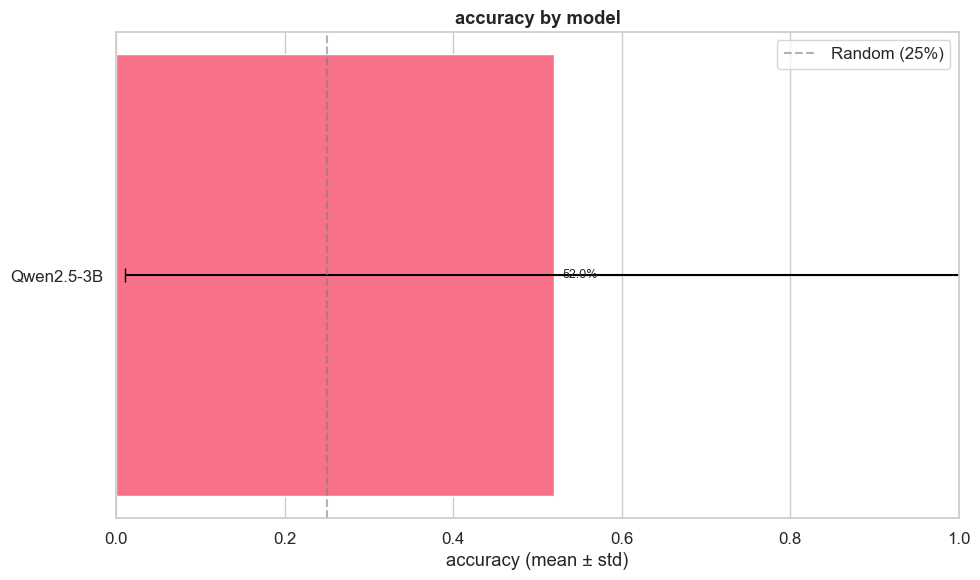

plots\02_accuracy_by_category.png


C:\Users\davyl\AppData\Local\Temp\ipykernel_19384\3682203996.py:49: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Arial.
  fig.tight_layout(); _save(fig, "02_accuracy_by_category")
C:\Users\davyl\AppData\Local\Temp\ipykernel_19384\3682203996.py:8: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Arial.
  fig.savefig(path, dpi=150, bbox_inches='tight')
c:\Users\davyl\Desktop\polimi\Quarto anno\II semestre\Natural Language Processing\NLP\venv\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


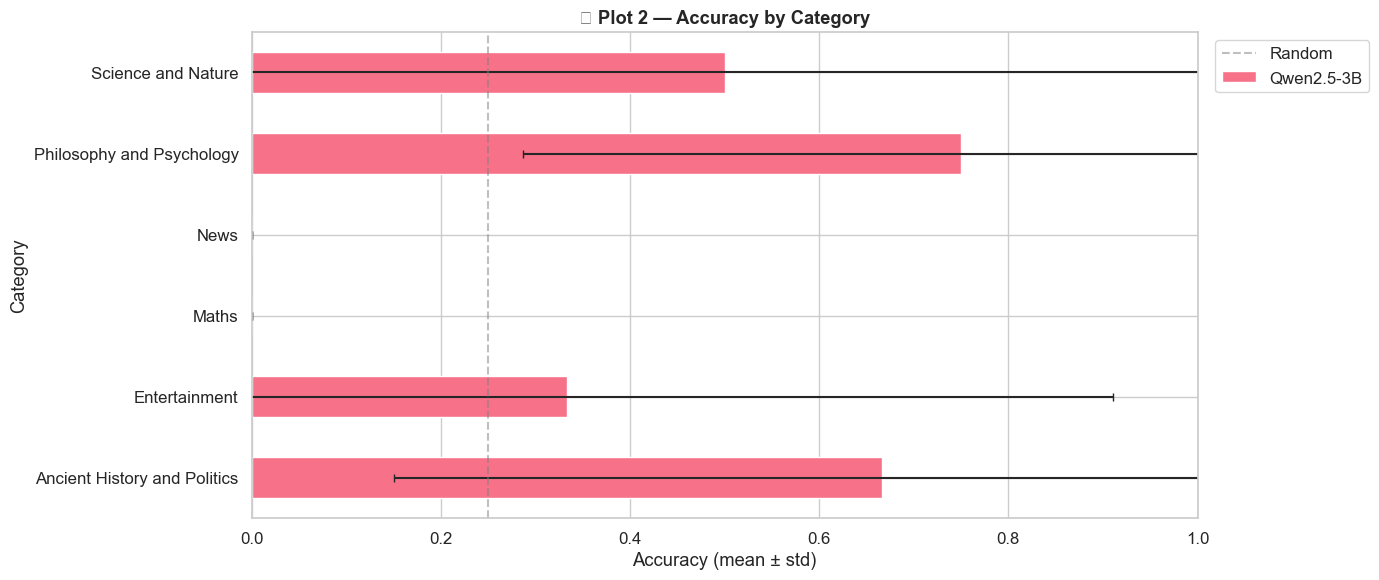

⚠️  Need multiple prompt_types. Skipping plot 3.


C:\Users\davyl\AppData\Local\Temp\ipykernel_19384\3682203996.py:97: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Arial.
  fig.tight_layout(); _save(fig, "04_accuracy_by_difficulty")
C:\Users\davyl\AppData\Local\Temp\ipykernel_19384\3682203996.py:8: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Arial.
  fig.savefig(path, dpi=150, bbox_inches='tight')


plots\04_accuracy_by_difficulty.png


c:\Users\davyl\Desktop\polimi\Quarto anno\II semestre\Natural Language Processing\NLP\venv\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


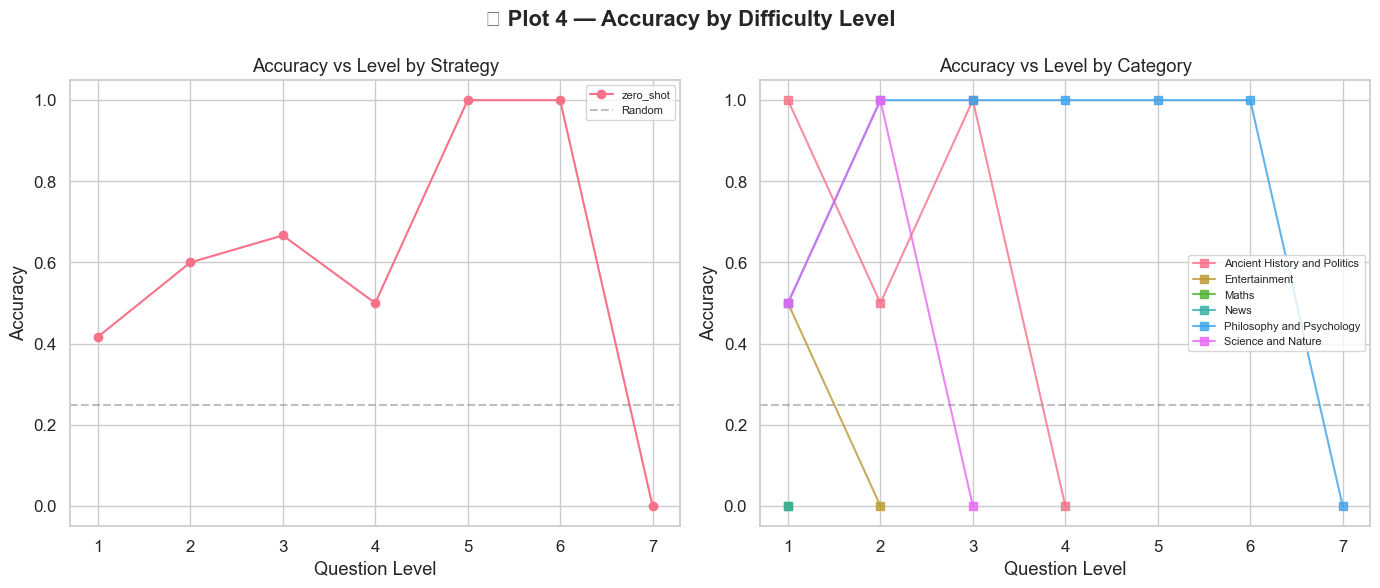

C:\Users\davyl\AppData\Local\Temp\ipykernel_19384\3682203996.py:146: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Arial.
  fig.tight_layout(); _save(fig, "05_calibration")
C:\Users\davyl\AppData\Local\Temp\ipykernel_19384\3682203996.py:8: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Arial.
  fig.savefig(path, dpi=150, bbox_inches='tight')


plots\05_calibration.png


c:\Users\davyl\Desktop\polimi\Quarto anno\II semestre\Natural Language Processing\NLP\venv\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


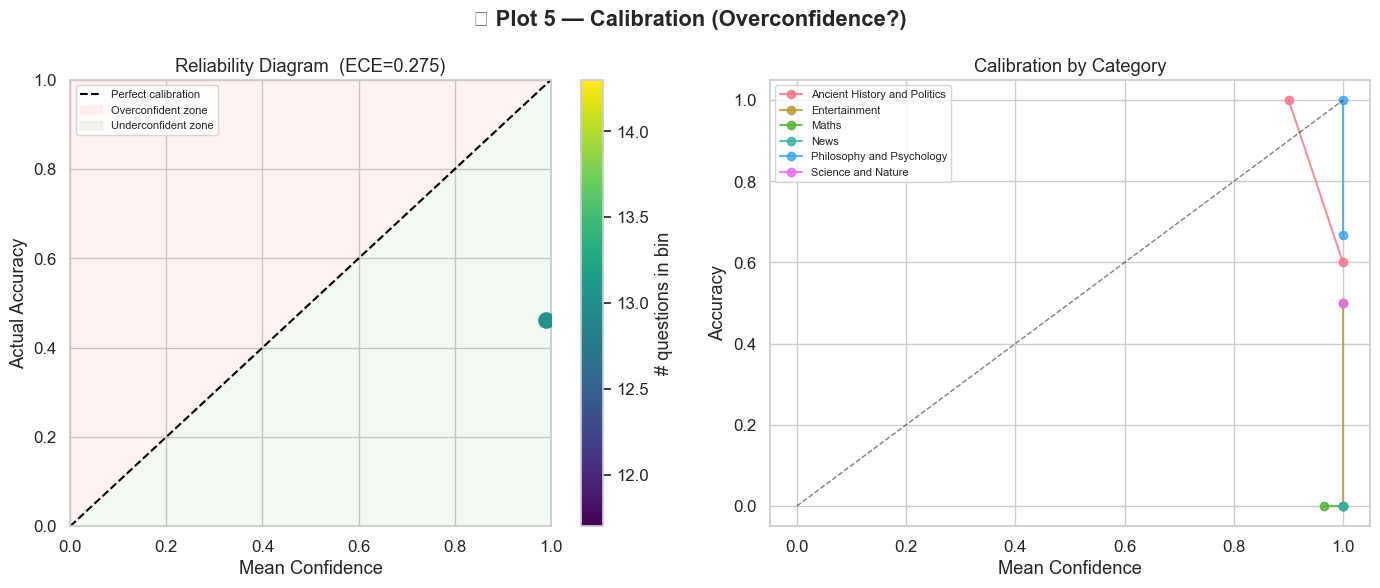

C:\Users\davyl\AppData\Local\Temp\ipykernel_19384\3682203996.py:173: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Arial.
  fig.tight_layout(); _save(fig, "06_confidence_distribution")


plots\06_confidence_distribution.png


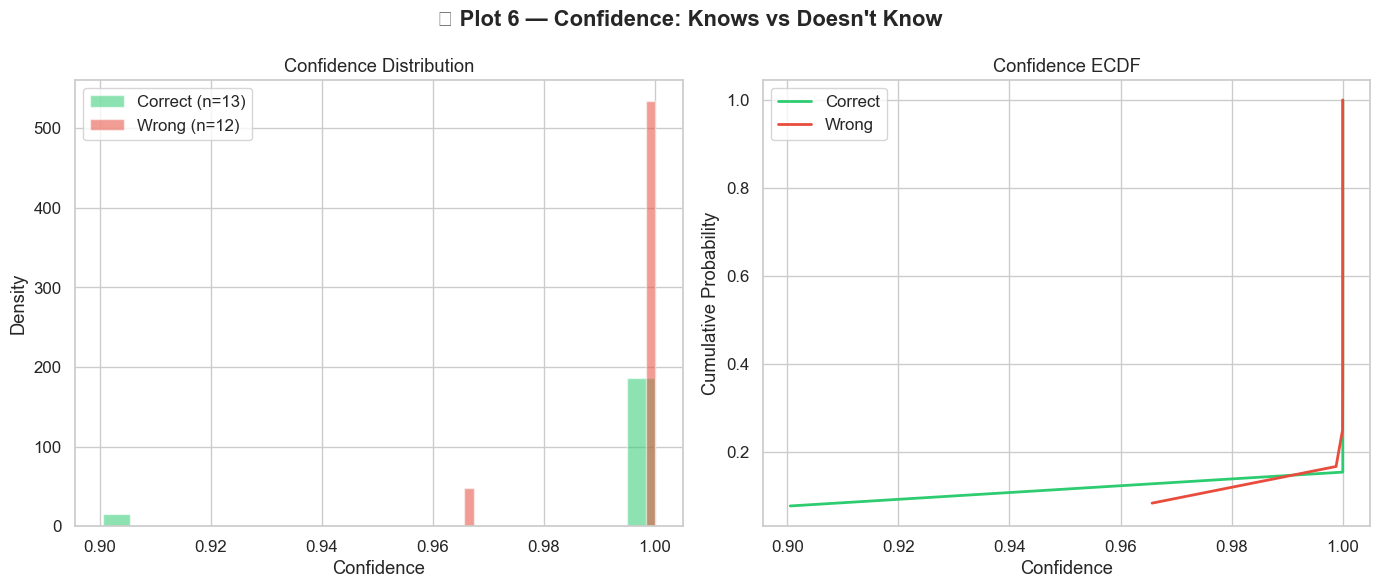

C:\Users\davyl\AppData\Local\Temp\ipykernel_19384\3682203996.py:203: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Arial.
  ax.legend(); fig.tight_layout(); _save(fig, "07_prob_correct_by_category")
C:\Users\davyl\AppData\Local\Temp\ipykernel_19384\3682203996.py:203: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  ax.legend(); fig.tight_layout(); _save(fig, "07_prob_correct_by_category")
C:\Users\davyl\AppData\Local\Temp\ipykernel_19384\3682203996.py:203: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  ax.legend(); fig.tight_layout(); _save(fig, "07_prob_correct_by_category")
C:\Users\davyl\AppData\Local\Temp\ipykernel_19384\3682203996.py:8: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Arial.
  fig.savefig(path, dpi=150, bbox_inches='tight')
C:\Users\davyl\AppData\Local\Temp\ipykernel_19384\3682203996.py:8: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  fig.savefig(path, dpi=150, b

plots\07_prob_correct_by_category.png


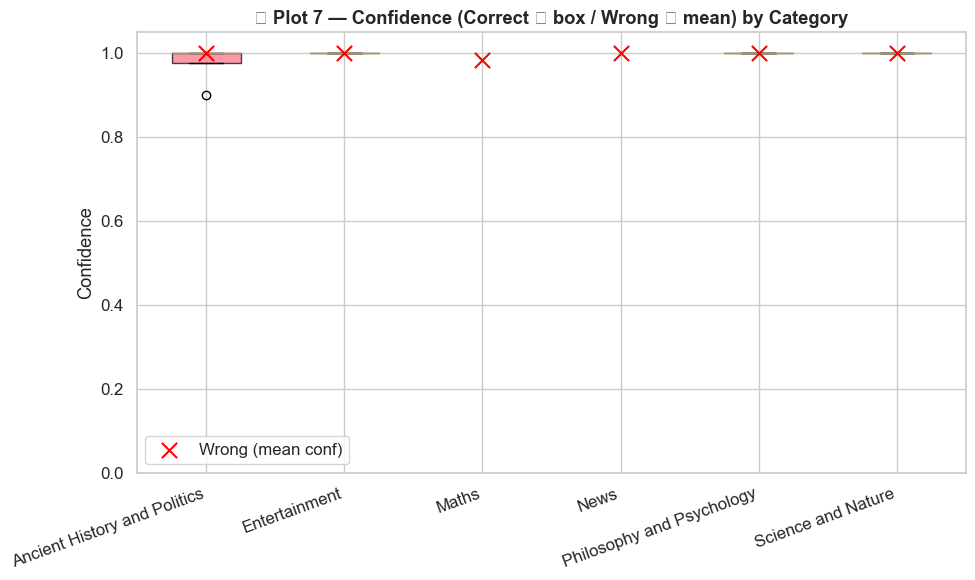

⚠️  Need RAG and non-RAG runs. Skipping plot 8.
plots\09_accuracy_vs_latency.png

C:\Users\davyl\AppData\Local\Temp\ipykernel_19384\3682203996.py:257: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Arial.
  ax.legend(); fig.tight_layout(); _save(fig, "09_accuracy_vs_latency")
C:\Users\davyl\AppData\Local\Temp\ipykernel_19384\3682203996.py:8: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Arial.
  fig.savefig(path, dpi=150, bbox_inches='tight')
c:\Users\davyl\Desktop\polimi\Quarto anno\II semestre\Natural Language Processing\NLP\venv\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


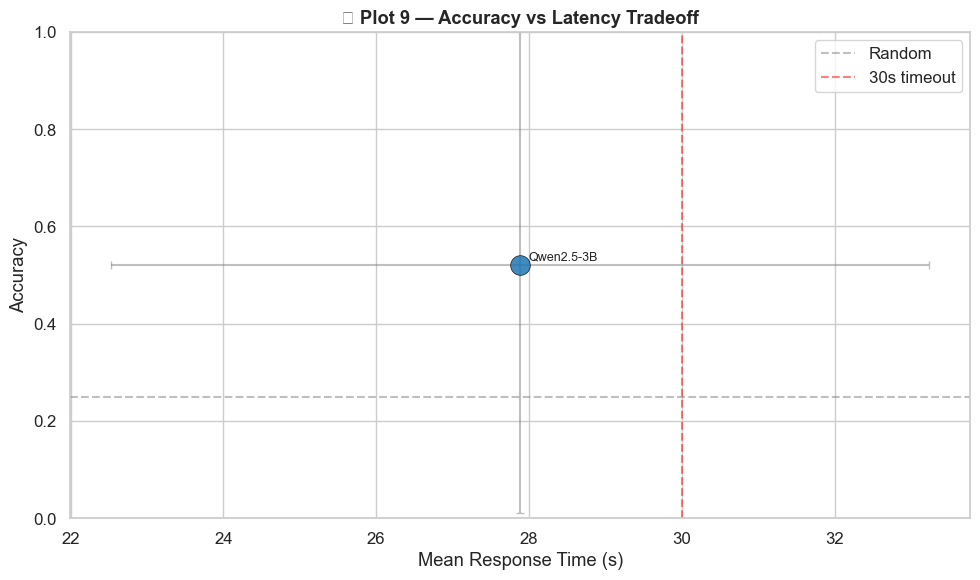

C:\Users\davyl\AppData\Local\Temp\ipykernel_19384\3682203996.py:282: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Arial.
  ax.legend(title='Quantization'); fig.tight_layout()
C:\Users\davyl\AppData\Local\Temp\ipykernel_19384\3682203996.py:8: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Arial.
  fig.savefig(path, dpi=150, bbox_inches='tight')
c:\Users\davyl\Desktop\polimi\Quarto anno\II semestre\Natural Language Processing\NLP\venv\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


plots\10_accuracy_by_model_size.png


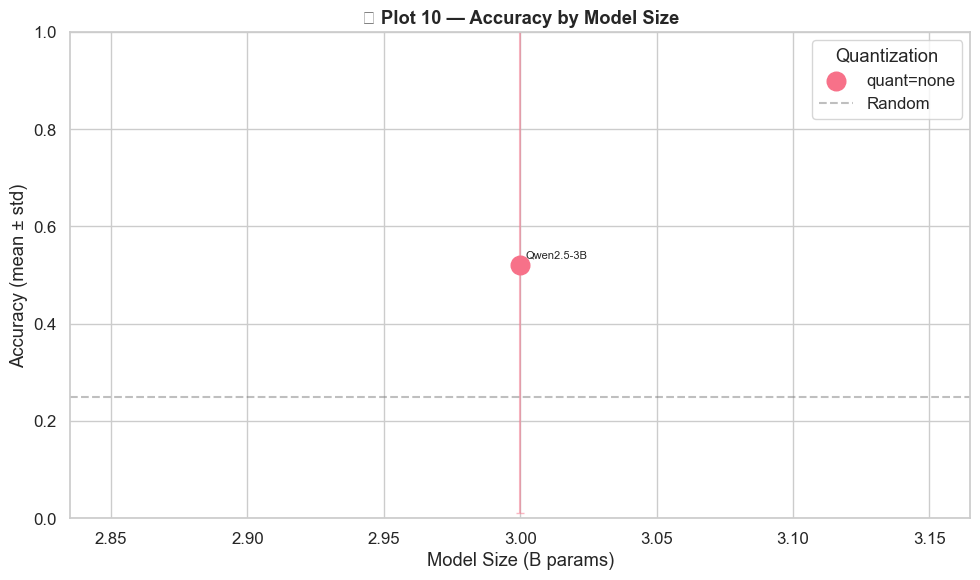

C:\Users\davyl\AppData\Local\Temp\ipykernel_19384\3682203996.py:310: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Arial.
  fig.tight_layout(); _save(fig, "11_letter_confusion")
C:\Users\davyl\AppData\Local\Temp\ipykernel_19384\3682203996.py:8: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Arial.
  fig.savefig(path, dpi=150, bbox_inches='tight')


plots\11_letter_confusion.png


c:\Users\davyl\Desktop\polimi\Quarto anno\II semestre\Natural Language Processing\NLP\venv\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


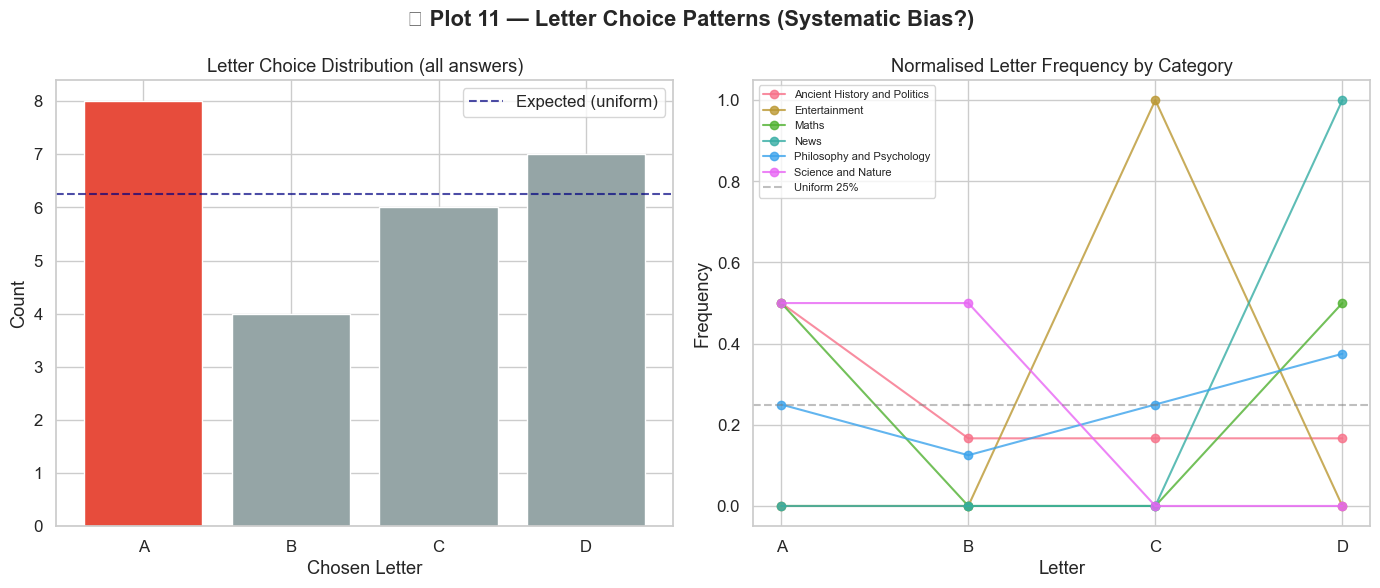

⚠️  Need thinking=True and False runs. Skipping plot 12.


C:\Users\davyl\AppData\Local\Temp\ipykernel_19384\3682203996.py:379: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Arial.
  fig.tight_layout(); _save(fig, "13_uncertainty_by_difficulty")
C:\Users\davyl\AppData\Local\Temp\ipykernel_19384\3682203996.py:8: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Arial.
  fig.savefig(path, dpi=150, bbox_inches='tight')


plots\13_uncertainty_by_difficulty.png


c:\Users\davyl\Desktop\polimi\Quarto anno\II semestre\Natural Language Processing\NLP\venv\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


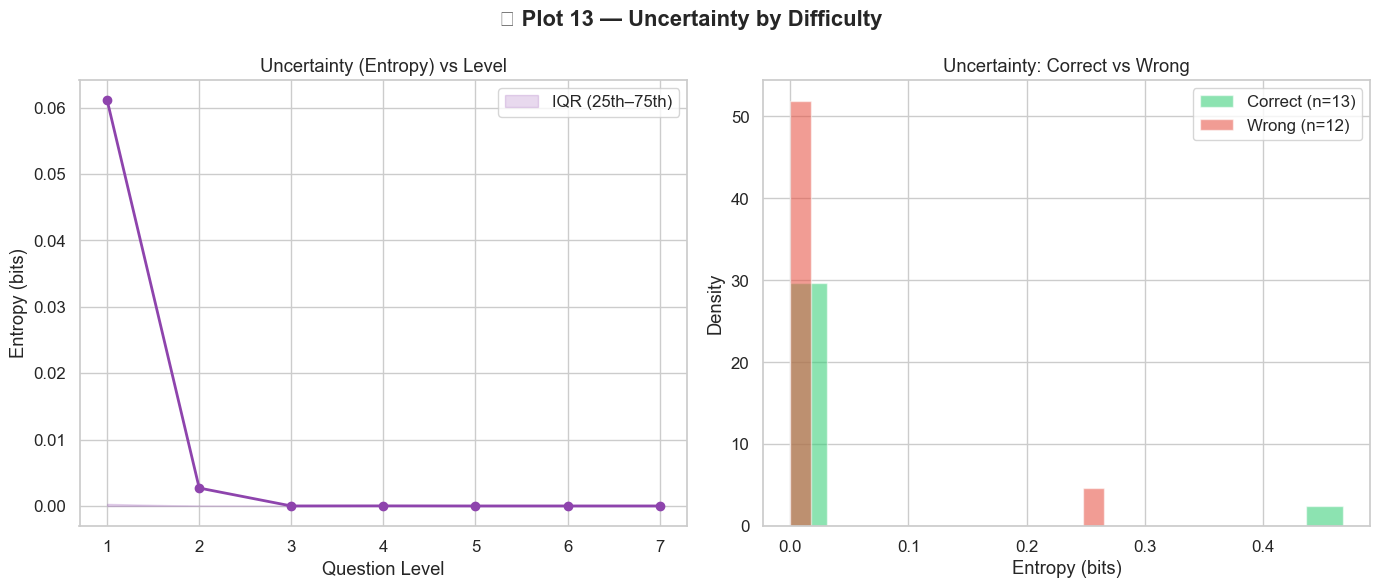

C:\Users\davyl\AppData\Local\Temp\ipykernel_19384\3682203996.py:391: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=labels, patch_artist=True)
C:\Users\davyl\AppData\Local\Temp\ipykernel_19384\3682203996.py:410: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Arial.
  fig.tight_layout(); _save(fig, "14_response_time")
C:\Users\davyl\AppData\Local\Temp\ipykernel_19384\3682203996.py:8: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Arial.
  fig.savefig(path, dpi=150, bbox_inches='tight')


plots\14_response_time.png


c:\Users\davyl\Desktop\polimi\Quarto anno\II semestre\Natural Language Processing\NLP\venv\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


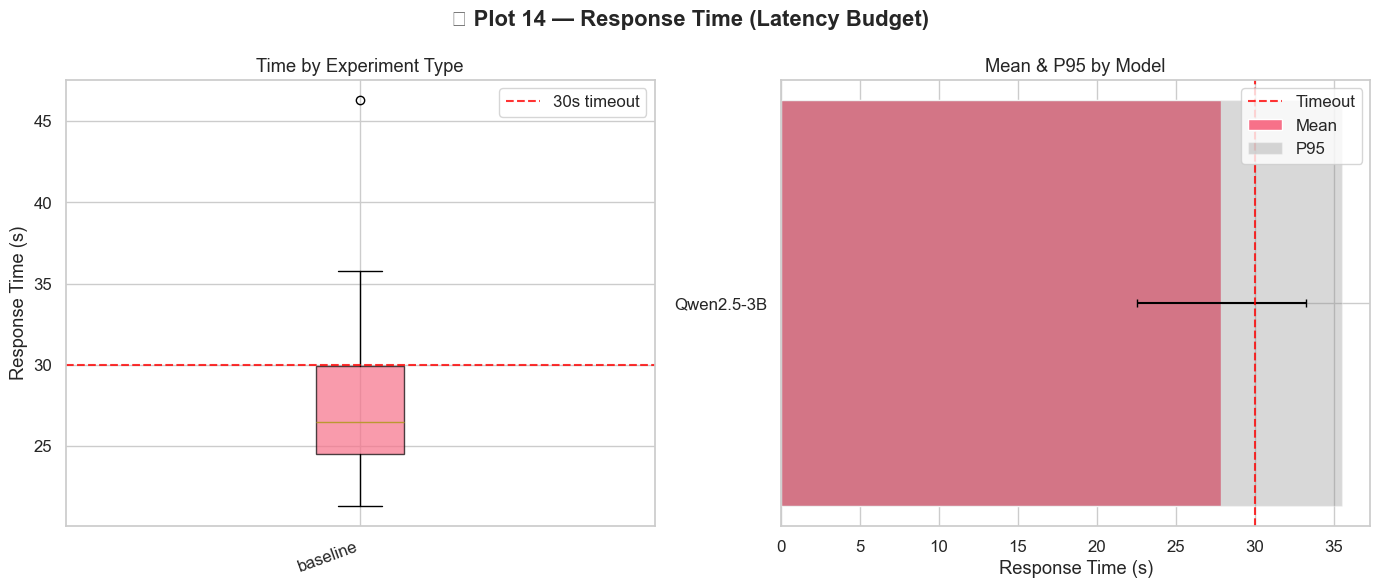

✅  All 14 plots generated!


In [59]:
df = load_runs('runs/run_20260525_155501_baseline_Qwen2.5-3B.json', 'runs/run_20260525_160212_baseline_Qwen2.5-3B.json')
df.head(25)
#print(df.groupby('model_name')['is_correct'].mean())
#print(df.shape)
#plot_all('runs/run_20260525_155501_baseline_Qwen2.5-3B.json', 'runs/run_20260525_160212_baseline_Qwen2.5-3B.json', 'runs/run_20260525_160643_baseline_Qwen2.5-3B.json')
plot_all('runs/run_20260525_155501_baseline_Qwen2.5-3B.json', 'runs/run_20260525_160212_baseline_Qwen2.5-3B.json')